# TV Cleaner: a Google TV's performance, version by version

A TCL Google TV (Android 12, 2 GB of RAM) went through five versions in four days, from the factory home screen to a
custom one with an animated, illustrated sky. Was each step faster or slower?

| Version | What it is |
|---|---|
| **V0** Google TV, factory | as it came: Google's home screen, every pre-installed extra on, normal animations |
| **V1** Google TV, cleaned up | 20 unused extras turned off (never uninstalled), animations at 0.5× |
| **V2** Free My TV, original | the open-source, ad-free home screen as published |
| V3, V4 | picks, title shelf, then the animated sky and weather (measured only at the time, see section 4) |
| **V5** Free My TV, this fork | sky, weather, lookout tower and music scenes |
| **V6** this fork, lighter sky | the same scenes, the sky painted at half resolution in its own layer, 10 frames a second |

V0, V1, V2, V5 and V6 were rebuilt on the TV the same day and put through **the same test** (`collector/benchmark.py`):
restart the TV, rest 3 minutes on the home screen, then measure memory, how fast the home screen comes back, 2 minutes
of moving around it with the arrows, and opening Netflix, Nuvio and Spotify.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False, "axes.spines.right": False})
D = "../datasets/"
ORDER = ["V0", "V1", "V2", "V5", "V6"]
COLOR = {"V0": "#9AA0A6", "V1": "#5F6368", "V2": "#72B7B2", "V5": "#F58518", "V6": "#B279A2"}
bench = pd.read_csv(D + "benchmark.csv")
frames = pd.read_csv(D + "benchmark_frames.csv")
apps = pd.read_csv(D + "benchmark_apps.csv")
names = bench.drop_duplicates("version").set_index("version")["label"]
mean = bench.groupby("version").mean(numeric_only=True).reindex(ORDER)
mean.insert(0, "label", names)
mean["runs"] = bench.groupby("version").size()
mean[["label", "runs", "boot_s", "mem_available_mb", "home_mb", "open_ms", "janky_pct", "frame_p50_ms"]].round(1)

,label,runs,boot_s,mem_available_mb,home_mb,open_ms,janky_pct,frame_p50_ms
version,,,,,,,,
V0,"Google TV, factory",1,37.0,854.0,200.0,138.0,2.4,14.0
V1,"Google TV, cleaned up",1,35.0,803.0,168.0,148.0,1.7,17.0
V2,"Free My TV, original",1,49.0,912.0,91.0,114.0,4.6,14.0
V5,"Free My TV, this fork",2,35.0,870.0,160.5,100.5,10.3,19.5
V6,"This fork, lighter sky",1,35.0,916.0,145.0,105.0,2.2,14.0


V5 ran twice (the numbers are the average); the others once. Single runs of the same version differ by
about 5 to 10%, so only differences bigger than that mean something.

## 1. Memory, start-up and the Home button

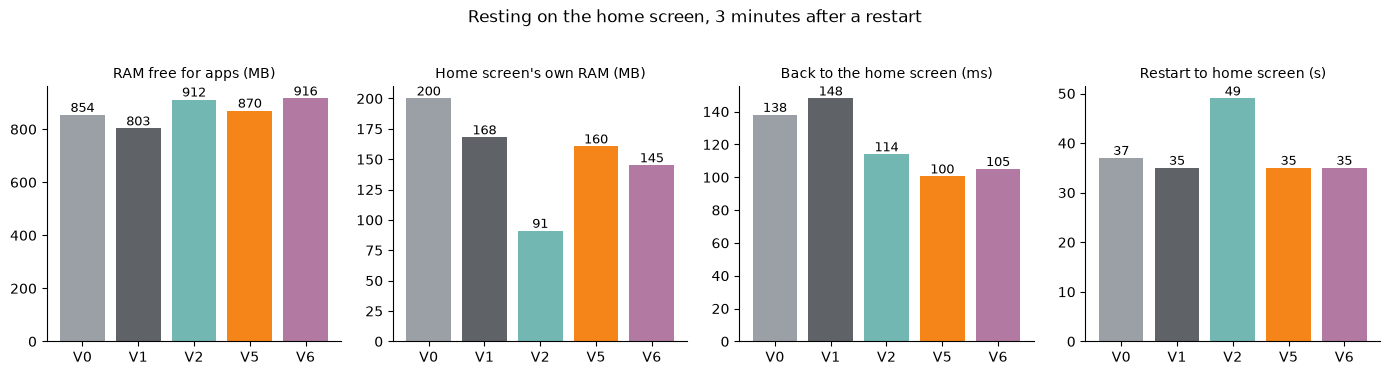

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (col, title) in zip(axes, [("mem_available_mb", "RAM free for apps (MB)"), ("home_mb", "Home screen's own RAM (MB)"),
                                   ("open_ms", "Back to the home screen (ms)"), ("boot_s", "Restart to home screen (s)")]):
    ax.bar(ORDER, mean[col], color=[COLOR[v] for v in ORDER])
    for x, v in enumerate(mean[col]):
        ax.text(x, v, f"{v:.0f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(title, fontsize=10)
fig.suptitle("Resting on the home screen, 3 minutes after a restart", y=1.03)
plt.tight_layout()
plt.show()

* **The home screen's own memory:** Google's uses 170 to 200 MB; the original Free My TV, 91 MB (half); this
  fork about 160 MB (V5), 145 MB with the lighter sky (V6): the illustrated sky and the tower cost about 55 MB over
  the original.
* **RAM free for apps** stays between 800 and 900 MB in every version: the differences are within the noise of a
  single run. Turning off the extras (V1) didn't free memory, because unused extras weren't running anyway.
* **Back to the home screen** is about 30% faster with Free My TV (about 100 ms against 140 to 150 ms). Pressing the remote's
  Home button, which goes through more of Android, shows a bigger gap: Free My TV's own settings measured **738 ms
  on Google's home screen against 96 ms** on Free My TV.
* **Restarting** takes 35 to 50 s in every version: the home screen isn't what slows it.

## 2. Smoothness (FPS) while moving around the home screen

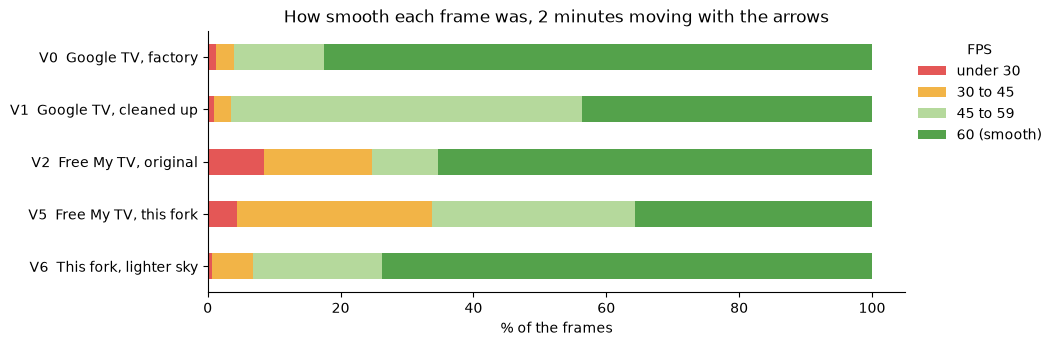

Average FPS: {'V0': 58.0, 'V1': 55.0, 'V2': 52.0, 'V5': 49.0, 'V6': 57.0}


In [3]:
def fps_bins(df):
    """Each frame's time as frames per second, in four bands."""
    fps = (1000 / df["frame_ms"].clip(lower=1000 / 60))
    band = pd.cut(fps, [0, 30, 45, 59, 61], labels=["under 30", "30 to 45", "45 to 59", "60 (smooth)"])
    return df.assign(band=band).groupby(["version", "band"], observed=False)["frames"].sum()

share = fps_bins(frames).unstack()
share = (100 * share.div(share.sum(axis=1), axis=0)).reindex(ORDER)
ax = share.plot.barh(stacked=True, color=["#E45756", "#F2B447", "#B5D99C", "#54A24B"], figsize=(9, 3.4))
ax.set(xlabel="% of the frames", ylabel="", title="How smooth each frame was, 2 minutes moving with the arrows")
ax.set_yticklabels([f"{v}  {names[v]}" for v in ORDER])
ax.invert_yaxis()
ax.legend(title="FPS", frameon=False, bbox_to_anchor=(1, 1))
plt.show()
avg = frames.assign(fps=1000 / frames["frame_ms"].clip(lower=1000 / 60))
avg = avg.groupby("version").apply(lambda g: np.average(g["fps"], weights=g["frames"]), include_groups=False)
print("Average FPS:", avg.reindex(ORDER).round(0).to_dict())

Google's factory home screen draws 83% of its frames at the full 60 fps (58 fps on average) and the original Free
My TV 65% (52 fps). V5 paid for its moving sky: 36% at 60 fps, **49 fps** on average, 10% of the frames late.

**Why, and the fix (V6).** Measured frame by frame, almost all the time went to the TV's graphics chip (an Amlogic
T5M), not to its processor: the sky had no layer of its own, so every frame of the shelf moving repainted the whole
sky (photo, clouds, trees, tower, rain, the dark veil). In V6 the sky is painted into its own small picture, at half
resolution (the background photo already was), only 10 times a second, on purpose, like a hand-drawn cartoon; every
other frame just stretches that picture. The open title's photo drifts at 20 frames a second instead of 30. Result:
**57 fps on average, 74% of the frames at 60, 2% late**, close to Google's home screen, with every scene kept.

## 3. Opening the apps

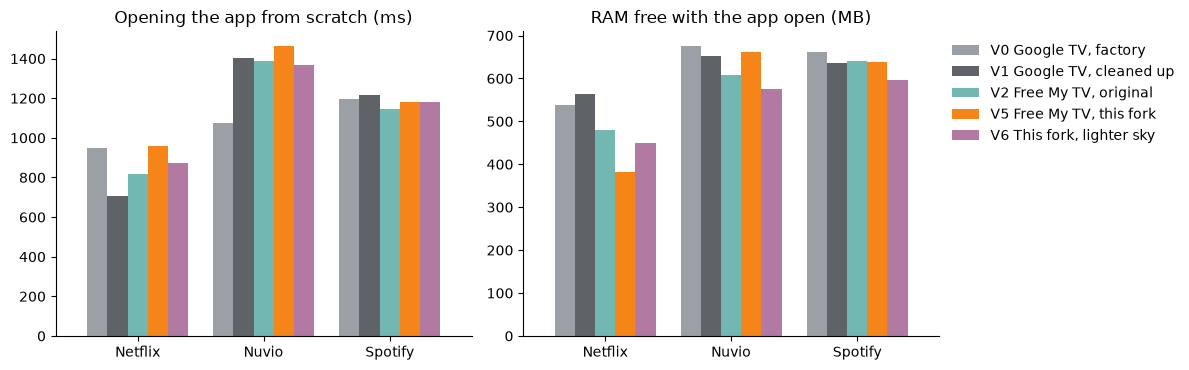

In [4]:
a = apps.groupby(["app", "version"]).mean(numeric_only=True).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (col, title) in zip(axes, [("launch_ms", "Opening the app from scratch (ms)"),
                                   ("mem_available_mb", "RAM free with the app open (MB)")]):
    t = a.pivot(index="app", columns="version", values=col)[ORDER]
    t.plot.bar(ax=ax, rot=0, color=[COLOR[v] for v in ORDER], width=0.8, legend=False)
    ax.set(title=title, xlabel="")
axes[1].legend([f"{v} {names[v]}" for v in ORDER], frameon=False, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

* **Opening the apps** takes about the same time in every version (Netflix about 0.9 s, Spotify 1.2 s, Nuvio
  1.1 to 1.5 s): the home screen behind them doesn't slow them down.
* **RAM with the app open** is lower with this fork: its home screen stays in memory behind the app, with the sky
  ready to come back. With Netflix open, about 380 MB stay free against 540 to 560 MB with Google's home screen. Android
  still has room: nothing was closed for lack of memory.

## 4. How the animated sky got light: the rain

The versions in between were measured at the time, while switching titles in the rain (the heaviest moment):

1. **First rain (V4):** three layers of drops drawn one by one, every frame, with the sky behind them redrawn too.
   39% of the frames came late, about 73 ms each (under 14 fps).
2. **Rain as a texture:** the drops became a ready-made picture that just slides, and the sky stands still while
   the titles move: 1% late, about 12 ms.
3. **Final version (V5):** the same, with the tower and music scenes: no frame late, about 10 ms.

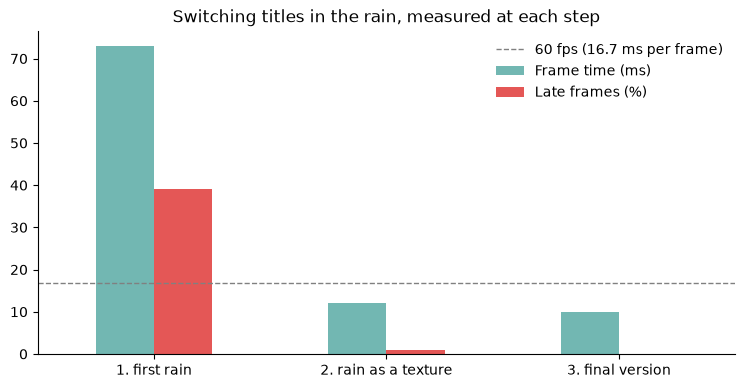

In [5]:
perf = pd.read_csv(D + "performance.csv")
fr = perf[perf["metric"].isin(["janky_pct", "frame_ms"])].pivot_table(index="stage", columns="metric", values="value", sort=False)
fr = fr[["frame_ms", "janky_pct"]].rename(columns={"frame_ms": "Frame time (ms)", "janky_pct": "Late frames (%)"})
fr.index = ["1. first rain", "2. rain as a texture", "3. final version"]
ax = fr.plot.bar(rot=0, color=["#72B7B2", "#E45756"])
ax.axhline(16.7, ls="--", c="gray", lw=1, label="60 fps (16.7 ms per frame)")
ax.set(xlabel="", title="Switching titles in the rain, measured at each step")
ax.legend(frameon=False)
plt.show()

## 5. Through the day (in progress)

The home screen now keeps its own log on the TV (one line every 15 minutes while the TV is on, even with the PC off),
which `collector/pull_tv_log.py` brings home. Below, the FPS by the sky's period of the day, from 10:00 to midnight,
when the TV is in use. It needs **2 to 4 weeks** of data to mean something; the evening, when the TV is used most,
will have the most frames.

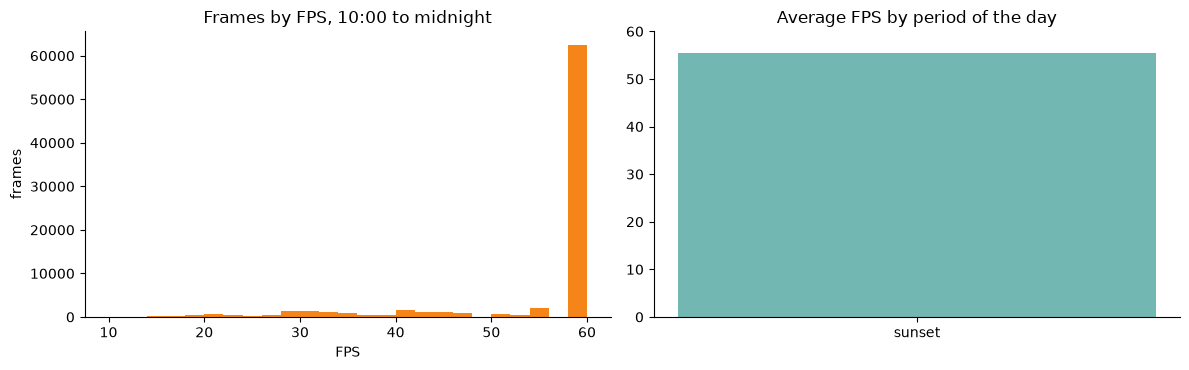

6 log lines over 1 day(s)


In [6]:
try:
    log = pd.read_csv(D + "tv_perf.csv")
except FileNotFoundError:
    log = pd.DataFrame()
if log.empty:
    print("No log yet.")
else:
    rows = []
    for _, r in log[(log["hour"] >= 10) & (log["frames"] > 0)].iterrows():
        for pair in str(r["histogram"]).split():
            ms, n = map(int, pair.split(":"))
            rows.append((r["period"], max(ms, 1), n))
    h = pd.DataFrame(rows, columns=["period", "frame_ms", "frames"])
    h["fps"] = 1000 / h["frame_ms"].clip(lower=1000 / 60)
    order = [p for p in ["morning", "midday", "sunset", "night"] if p in set(h["period"])]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
    a1.hist(h["fps"], bins=range(10, 62, 2), weights=h["frames"], color="#F58518")
    a1.set(title="Frames by FPS, 10:00 to midnight", xlabel="FPS", ylabel="frames")
    by = h.groupby("period").apply(lambda g: np.average(g["fps"], weights=g["frames"]), include_groups=False)
    a2.bar(order, by[order], color="#72B7B2")
    a2.set(title="Average FPS by period of the day", ylim=(0, 60))
    plt.tight_layout()
    plt.show()
    print(f"{len(log)} log lines over {log['day'].nunique()} day(s)")